<a href="https://colab.research.google.com/github/lmassaron/fine-tuning-workshop/blob/main/reasoned-financial-sentiment/02_fine_tuning_sentiment%20(b).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fine-Tune Gemma 4 E2B-IT for Reasoned Financial Sentiment Analysis (CoT)

This tutorial covers the **fine-tuning process** of the **Gemma 4 E2B-IT** model for **reasoned sentiment analysis** on financial and economic news headlines using **TRL** and **4-bit QLoRA**. Sentiment analysis in this domain is crucial for businesses for several reasons, including:

- **Market Insights**: Gaining valuable insights into market trends, investor confidence, and consumer behavior.
- **Risk Management**: Identifying potential reputational risks.
- **Investment Decisions**: Assessing the sentiment of stakeholders, investors, and the general public to evaluate investment opportunities.

### Objectives
- Inject structured **Chain-of-Thought (CoT) reasoning** into a financial sentiment classification task.
- Establish a **zero-shot baseline** before fine-tuning and compare it against post-training metrics (accuracy, per-class F1, confusion matrix, and tag integrity).
- Perform **Supervised Fine-Tuning (SFT)** using Hugging Face `trl` and `peft` libraries, optimized to fit within a **16GB VRAM** constraint.
- Save, merge, compare disk footprints, and qualitatively inspect the model's generated financial explanations.

Before diving into the technical aspects of fine-tuning a large language model like **Gemma**, we must first understand our **dataset**.

## Introducing Gemma 4 E2B-IT

**Gemma 4 E2B-IT** (`google/gemma-4-E2B-it`) is an instruction-tuned lightweight open model designed to deliver strong reasoning and text generation capabilities while remaining resource-efficient. When combined with **4-bit NormalFloat (NF4) quantization** and **Low-Rank Adaptation (LoRA)**, it can be fine-tuned comfortably on a single consumer or Colab GPU with 16GB of VRAM.

## Dataset Selection

Annotated datasets for finance and economic texts are relatively rare, with many being proprietary. To address this challenge, researchers from the **Aalto University School of Business** introduced the **FinancialPhraseBank Dataset** in 2014, which contains approximately **5,000 sentences**.

This dataset provides **human-annotated benchmarks**, allowing for consistent evaluation of different modeling techniques. The annotations were performed by **16 individuals** with a background in **financial markets**, who categorized the sentences as having a:

- **Positive** impact on stock prices
- **Negative** impact on stock prices
- **Neutral** impact on stock prices

The impact was assessed from an **investor's perspective**.

## More on the FinancialPhraseBank Dataset

The **FinancialPhraseBank** dataset is a comprehensive collection of **financial news headlines** analyzed from the viewpoint of **retail investors**. It includes two key columns:

- **Sentiment**: Classified as **negative**, **neutral**, or **positive**.
- **News Headline**: The actual **financial news snippet**.

This dataset has been widely used in research, including the study by **Malo, P.**, **Sinha, A.**, **Korhonen, P.**, **Wallenius, J.**, and **Takala, P.**, titled "*Good Debt or Bad Debt: Detecting Semantic Orientations in Economic Texts*" (published in the **Journal of the Association for Information Science and Technology**, 2014).

## Required Libraries

To implement this tutorial, we first inspect the available GPU and install the essential libraries:

In [1]:
import platform

if platform.system() != "Darwin":
    # Check the GPU information
    !nvidia-smi

Now we install the required Python libraries when running in Google Colab. The `%%capture` magic suppresses the lengthy installation output.

In [2]:
%%capture
# Install necessary libraries for model training and evaluation
import os

if "COLAB_" not in "".join(os.environ.keys()):
    pass
else:
    !pip install -U transformers trl peft accelerate bitsandbytes datasets

### Explanation of Key Libraries

- **`transformers`**: Provides a framework to handle **pre-trained NLP models** for tasks like **text classification** and **text generation**.
- **`accelerate`**: A distributed training library by Hugging Face designed for **parallelizing training** across multiple **GPUs or CPUs**.
- **`peft`**: A library for **parameter-efficient fine-tuning (PEFT)** of pre-trained language models, including support for **LoRA (Low-Rank Adaptation)**.
- **`trl`**: A Hugging Face library for training **transformer models** with **supervised fine-tuning** or **reinforcement learning techniques**.
- **`bitsandbytes`**: A lightweight library that provides custom CUDA functions for **8-bit and 4-bit quantization** of PyTorch models. This significantly reduces the memory footprint of large language models, enabling QLoRA training on limited VRAM hardware without compromising performance.
- **`datasets`**: Provides efficient loading, preprocessing, and mapping of Hugging Face Hub datasets.

## Suppressing Warnings

During training, several warnings may appear that do not impact the fine-tuning process but can be distracting. To suppress them:

In [3]:
# Suppress non-critical warnings to keep notebook output clean
import warnings

warnings.filterwarnings("ignore")

## Demo Mode

The `DEMO` flag controls how much data is used during training:

- `DEMO = True` — uses 450 balanced training / 60 validation / 60 test examples (150 / 20 / 20 per class). Finishes in ~8–10 minutes on a Colab T4 while still demonstrating clear fine-tuning gains.
- `DEMO = False` — uses the full dataset. Recommended for a meaningful fine-tuning run.

In [4]:
# DEMO=False -> use the full dataset for training.
# DEMO=True  -> limit data for a quick smoke-test.
DEMO = True

## Importing Necessary Libraries

The following Python libraries are required for running the fine-tuning and evaluation process:

In [5]:
# Numeric and data utilities
import gc
import math
import os
import re  # regular expressions for parsing model output tags
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

# PyTorch
import torch

# Hugging Face Transformers
import transformers
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,  # 4-bit quantization configuration
)

# Hugging Face ecosystem
from datasets import Dataset, load_dataset
from huggingface_hub import login
from peft import LoraConfig  # LoRA fine-tuning configuration
from trl import SFTConfig, SFTTrainer  # supervised fine-tuning trainer

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

W1127 04:42:28.671000 87012 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


To check the installed version of the `transformers` library:

In [6]:
# Print the installed transformers version to confirm it matches the expected environment
print(f"transformers=={transformers.__version__}")

transformers==5.23.0


This function determines the best computing device for running the tutorial, followed by an initialization helper that logs in to Hugging Face and clears stale GPU memory:

In [7]:
def define_device():
    """Determines and returns the optimal PyTorch device based on hardware availability."""
    print(f"PyTorch version: {torch.__version__}", end=" -- ")

    # Prefer MPS (Metal Performance Shaders) on Apple Silicon Macs
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        print("using MPS device on macOS")
        return torch.device("mps")

    # Fall back to CUDA (NVIDIA GPU) or CPU
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"using {device}")
    return device

In [8]:
def init():
    """Sets environment variables, logs in to Hugging Face, and clears GPU memory."""
    os.environ["TOKENIZERS_PARALLELISM"] = "false"  # avoid deadlocks in forked tokenizer processes
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # pin to the first GPU

    token = os.environ.get("HF_TOKEN")
    if token:
        login(token=token)
    else:
        try:
            from google.colab import userdata

            # Read the token stored in Colab's Secrets tab
            hf_token = userdata.get("HF_TOKEN")
            if hf_token:
                login(token=hf_token, add_to_git_credential=True)
                print("Hugging Face login successful using Google Colab secrets!")
            else:
                print("Error: HF_TOKEN not found in Google Colab secrets or is empty.")
                print("Please ensure you have created a secret named 'HF_TOKEN' in the 'Secrets' tab.")
        except Exception as e:
            print(f"Could not read HF_TOKEN from Colab secrets ({e}).")
            print("You might need to log in manually via huggingface_hub.login().")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()  # release any stale GPU allocations from a previous run
    gc.collect()
    warnings.filterwarnings("ignore")


init()

Could not read HF_TOKEN from Colab secrets (No module named 'google').
You might need to log in manually via huggingface_hub.login().


## Loading Gemma 4 E2B-IT with 4-Bit Quantization (QLoRA)

This code initializes the **Gemma 4 E2B-IT** model for causal language modeling, selecting optimal settings based on available hardware:

* **Compute dtype**: `bfloat16` is used on GPUs with Compute Capability ≥ 8.0 (Ampere and newer); older GPUs fall back to `float16`.
* **Device selection**: `define_device()` picks the best available device (CUDA > MPS > CPU).
* **4-bit quantization (QLoRA)**: `BitsAndBytesConfig` loads the base model in NF4 4-bit precision with double quantization to fit comfortably within a **16GB VRAM** budget while keeping LoRA adapters in higher precision.
* **Sequence length**: `MAX_SEQ_LENGTH = 512` covers the financial headlines and CoT explanations while keeping memory usage low.

In [9]:
# Choose computation dtype based on GPU capability
if torch.cuda.is_available():
    compute_dtype = (
        torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    )
else:
    compute_dtype = torch.bfloat16

print(f"Using compute dtype {compute_dtype}")

# Select the best available device
device = define_device()
print(f"Operating on {device}")

MODEL_ID = "google/gemma-4-E2B-it"
MAX_SEQ_LENGTH = 320 if DEMO else 512  # 320 covers headlines + CoT and speeds up T4 runs

# 4-bit quantization configuration (QLoRA)
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True,
)

# Use eager attention: Gemma4AudioModel does not support SDPA, and eager also prevents
# left-padding NaNs on float16 (T4) during batched generation
attn_impl = "eager"
print(f"Using attention implementation: {attn_impl}")

# Load the base model
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=compute_dtype,
    quantization_config=quantization_config,
    attn_implementation=attn_impl,
    device_map="auto",
)

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

EOS_TOKEN = tokenizer.eos_token

Using compute dtype torch.bfloat16
PyTorch version: 2.15.0 -- using MPS device on macOS
Operating on mps
Using attention implementation: eager


Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

Print a detailed summary of the loaded model to confirm the quantization settings are active.

In [10]:
# Confirm the loaded model name, device placement, data type, and 4-bit quantization
print(f"Model: {model.name_or_path}")
print(f"Device: {model.device}")
print(f"DType: {model.dtype}")

if hasattr(model, "is_quantized") and model.is_quantized:
    print("Quantization: Enabled")
    print(f"  - 4bit: {model.is_loaded_in_4bit}")
    print(f"  - Quant Type: {model.hf_quantizer.quantization_config.bnb_4bit_quant_type}")
    print(f"  - Compute DType: {model.hf_quantizer.quantization_config.bnb_4bit_compute_dtype}")
else:
    print("Quantization: Disabled")

Model: google/gemma-4-E2B-it
Device: mps:0
DType: torch.bfloat16
Quantization: Enabled
  - 4bit: True
  - Quant Type: nf4
  - Compute DType: torch.bfloat16


Before proceeding, let's ensure that the entire model is correctly placed on the GPU.

In [11]:
# Sanity-check: confirm that all model parameters are on the GPU (CUDA or MPS)
is_on_gpu = all(param.device.type in ("cuda", "mps") for param in model.parameters())
print("Model is on GPU:", is_on_gpu)

Model is on GPU: True


## Loading the Dataset

We load **`lmassaron/FinancialPhraseBank_explained`** directly from the Hugging Face Hub. This is an enriched version of the original FinancialPhraseBank dataset that adds an LLM-generated `explanation` column alongside the human-annotated `sentiment` and `sentence` columns.

The Hub dataset already provides **pre-split** `train`, `validation`, and `test` splits. For the **test split**, we explicitly filter out any augmented rows (`is_augmented == False`) so that both our baseline and post-training benchmarks are measured strictly on the **484 original FinancialPhraseBank headlines**.

In [12]:
DATASET_ID = "lmassaron/FinancialPhraseBank_explained"
print(f"Loading {DATASET_ID}...")
ds = load_dataset(DATASET_ID)


def to_clean_df(split, filter_augmented=False):
    df = split.to_pandas().rename(
        columns={"sentence": "text", "explanation": "reasoning"}
    )
    if filter_augmented and "is_augmented" in df.columns:
        df = df[df["is_augmented"] == False].reset_index(drop=True)
    return df[["sentiment", "text", "reasoning"]]


X_train_df = to_clean_df(ds["train"])
X_eval_df = to_clean_df(ds["validation"])
# Filter out augmented samples from test split for clean evaluation
X_test_df = to_clean_df(ds["test"], filter_augmented=True)

print(f"Train rows : {len(X_train_df)}")
print(f"Eval rows  : {len(X_eval_df)}")
print(f"Test rows  : {len(X_test_df)} (original non-augmented headlines)")
print("\nSample sentence   :", X_train_df.iloc[0]["text"])
print("Sample sentiment  :", X_train_df.iloc[0]["sentiment"])
print("Sample explanation:", X_train_df.iloc[0]["reasoning"])

Loading lmassaron/FinancialPhraseBank_explained...


README.md:   0%|          | 0.00/679 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.90MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  244kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/7902 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/988 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/985 [00:00<?, ? examples/s]

Train rows : 7902
Eval rows  : 988
Test rows  : 484 (original non-augmented headlines)

Sample sentence   : The shares carry a right to dividend and other shareholder rights as from their registration with the Finnish Trade Register .
Sample sentiment  : neutral
Sample explanation: The inclusion of a right to dividend and other shareholder rights indicates that the shares have reached a status where they are eligible for dividends and certain voting rights. This typically does not directly impact revenue or profitability but can enhance investor confidence by providing clear entitlements and potentially increasing the perceived value of the shares, thus maintaining a neutral sentiment in terms of market reaction.


## Prompt Engineering (Chain-of-Thought Formatting)

We structure the news headline, analyst instructions, and target `<sentiment>` / `<reasoning>` tags into Gemma 4's chat template using `tokenizer.apply_chat_template`.

- **`generate_train_prompt`**: Includes both the user prompt and the assistant's structured answer (`add_generation_prompt=False`).
- **`generate_test_prompt`**: Includes only the user prompt and appends the model turn marker (`add_generation_prompt=True`).
- **`extract_tag`**: Uses regular expressions to parse `<sentiment>...</sentiment>` and `<reasoning>...</reasoning>` from generated text.

> **Tip on CoT Ordering:** By default, this template outputs `<sentiment>` followed by `<reasoning>` (matching both source notebooks). If you want the reasoning tokens to actively condition the sentiment label during generation (true Chain-of-Thought), simply swap the order of `<reasoning>` and `<sentiment>` in `SYSTEM_PROMPT` and `generate_train_prompt`.

In [13]:
SYSTEM_PROMPT = (
    "You are a financial analyst with expertise in equity markets and corporate finance.\n"
    "Analyze the following financial news headline and determine its market sentiment "
    "from an investor's perspective.\n\n"
    "Classify the sentiment as positive, neutral, or negative based on the likely "
    "impact on stock price, investor confidence, or financial performance.\n\n"
    "Respond using exactly these two tags:\n"
    "<sentiment>positive|neutral|negative</sentiment>\n"
    "<reasoning>brief financial explanation</reasoning>\n"
)


def generate_test_prompt(data_point):
    """Generates a test/inference prompt ending at the model turn marker."""
    messages = [
        {
            "role": "user",
            "content": SYSTEM_PROMPT + f'\nHeadline: "{data_point["text"]}"',
        },
    ]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


def generate_sft_example(data_point):
    """Returns separate prompt and completion strings so SFTTrainer masks prompt loss."""
    return {
        "prompt": generate_test_prompt(data_point),
        "completion": (
            f"<sentiment>{data_point['sentiment']}</sentiment>\n"
            f"<reasoning>{data_point['reasoning']}</reasoning><turn|>"
        ),
    }


def extract_tag(text, tag):
    """Extracts content of the first <tag>...</tag> occurrence."""
    match = re.search(rf"<{tag}>(.*?)</{tag}>", text, re.IGNORECASE | re.DOTALL)
    return match.group(1).strip() if match else None

Apply the prompt templates to transform the raw DataFrames into formatted strings ready for training and inference, and preview the first training example.

In [14]:
# In DEMO mode, sample a shuffled, balanced subset sized for a ~8-10 min classroom run
if DEMO:
    def stratified_sample(df, label_col, n_per_class, seed=42):
        groups = [
            g.sample(min(len(g), n_per_class), random_state=seed)
            for _, g in df.groupby(label_col)
        ]
        # Shuffle combined classes so qualitative previews show mixed sentiments
        return (
            pd.concat(groups)
            .sample(frac=1, random_state=seed)
            .reset_index(drop=True)
        )

    X_train_df = stratified_sample(X_train_df, "sentiment", n_per_class=150)  # 450 total
    X_eval_df = stratified_sample(X_eval_df, "sentiment", n_per_class=20)     # 60 total
    X_test_df = stratified_sample(X_test_df, "sentiment", n_per_class=20)     # 60 total
    print("DEMO mode — class distribution in training set:")
    print(X_train_df["sentiment"].value_counts())

# Build prompt/completion datasets for completion-only loss in SFTTrainer
train_data = Dataset.from_list(
    [generate_sft_example(row) for _, row in X_train_df.iterrows()]
)
eval_data = Dataset.from_list(
    [generate_sft_example(row) for _, row in X_eval_df.iterrows()]
)

# Store ground-truth test labels separately and format inference prompts
y_true = X_test_df["sentiment"].tolist()
X_test = pd.DataFrame(X_test_df.apply(generate_test_prompt, axis=1), columns=["text"])

print("\nMapped Prompt Preview:\n")
print(train_data[0]["prompt"] + train_data[0]["completion"])

DEMO mode — class distribution in training set:
sentiment
positive    150
negative    150
neutral     150
Name: count, dtype: int64

Mapped Prompt Preview:

<bos><|turn>user
You are a financial analyst with expertise in equity markets and corporate finance.
Analyze the following financial news headline and determine its market sentiment from an investor's perspective.

Classify the sentiment as positive, neutral, or negative based on the likely impact on stock price, investor confidence, or financial performance.

Respond using exactly these two tags:
<sentiment>positive|neutral|negative</sentiment>
<reasoning>brief financial explanation</reasoning>

Headline: "The brokerage said 2006 has seen a ` true turning point ' in European steel base prices , with better pricing seen carrying through the second quarter of 2006 ."<turn|>
<|turn>model
<sentiment>positive</sentiment>
<reasoning>The headline indicates an improvement in European steel pricing, suggesting stronger demand and higher re

## Evaluation & CoT Prediction Functions

The `evaluate` function measures the performance of our sentiment analysis model by performing the following tasks:

**1. Map Sentiment Labels to Numeric Values**
- **Positive** → `2`
- **Neutral** → `1`
- **Negative** → `0`
- Handles malformed or `'none'` predictions by mapping them to **`1 (neutral)`**.

**2. Calculate Overall Accuracy & Tag Integrity**
- Computes overall sentiment accuracy and, when provided, the **Tag Integrity** score (percentage of responses containing both valid `<sentiment>` and `<reasoning>` tags).

**3. Compute Accuracy for Each Sentiment Label**
- Extracts per-class accuracy separately for **Negative**, **Neutral**, and **Positive**.

**4. Generate a Classification Report**
- Prints **precision, recall, and F1-score** for each sentiment category.

**5. Compute and Display the Confusion Matrix**
- Displays a **confusion matrix** to reveal misclassification patterns (e.g., predicting **neutral** instead of **positive**).

In [15]:
def evaluate(y_true, y_pred, tag_integrity=None):
    """Evaluates sentiment accuracy, macro-F1, tag integrity, and unparsed outputs."""
    from sklearn.metrics import f1_score

    label_mapping = {"negative": 0, "neutral": 1, "positive": 2}
    reverse_map = {v: k for k, v in label_mapping.items()}

    # Map unparsed ('none') predictions to -1 so they count as wrong, not 'neutral'
    y_true_num = np.array([label_mapping[label] for label in y_true])
    y_pred_num = np.array([label_mapping.get(label, -1) for label in y_pred])

    invalid_count = int(np.sum(y_pred_num == -1))
    accuracy = accuracy_score(y_true_num, y_pred_num)
    macro_f1 = f1_score(
        y_true_num, y_pred_num, labels=[0, 1, 2], average="macro", zero_division=0
    )
    integrity_rate = float(np.mean(tag_integrity)) if tag_integrity is not None else None

    print(f"Overall Accuracy : {accuracy:.3f} ({accuracy:.2%})")
    print(f"Macro F1-Score   : {macro_f1:.3f} ({macro_f1:.2%})")
    if integrity_rate is not None:
        print(f"Tag Integrity    : {integrity_rate:.3f} ({integrity_rate:.2%})")
    print(f"Unparsed ('none'): {invalid_count}/{len(y_pred)} ({invalid_count / len(y_pred):.1%})")

    for label in [0, 1, 2]:
        label_mask = y_true_num == label
        label_accuracy = accuracy_score(y_true_num[label_mask], y_pred_num[label_mask])
        print(f"Accuracy for label {label} ({reverse_map[label]}): {label_accuracy:.3f}")

    class_report = classification_report(
        y_true_num,
        y_pred_num,
        labels=[0, 1, 2],
        target_names=list(label_mapping.keys()),
        zero_division=0,
    )
    print("\nClassification Report:\n", class_report)

    conf_matrix = confusion_matrix(y_true_num, y_pred_num, labels=[0, 1, 2])
    print("Confusion Matrix (rows=true, cols=pred [neg, neu, pos]):\n", conf_matrix)

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "tag_integrity": integrity_rate,
        "unparsed": invalid_count,
    }

The `predict_with_reasoning` function runs batched inference to generate both the `<sentiment>` label and the `<reasoning>` explanation.

### Function Workflow:
1. **Left-Padding for Batched Generation**: Temporarily sets `tokenizer.padding_side = "left"` so decoder-only generation works accurately across batches, then restores the original setting afterward.
2. **Deterministic Generation**: Uses `do_sample=False` when `temperature=0.0` with `max_new_tokens=150` (configurable) so the model has enough token budget to complete both tags.
3. **Structured Tag Extraction**: Parses `<sentiment>` and `<reasoning>` via `extract_tag`, tracks `tag_integrity`, and falls back to keyword matching if tags are malformed.

In [16]:
def _get_stop_token_ids(tokenizer):
    """Collects EOS and Gemma turn-end token IDs so generation stops right after </reasoning>."""
    stop_ids = []
    if tokenizer.eos_token_id is not None:
        if isinstance(tokenizer.eos_token_id, list):
            stop_ids.extend(tokenizer.eos_token_id)
        else:
            stop_ids.append(tokenizer.eos_token_id)
    for tok in ("<turn|>", "<end_of_turn>"):
        tid = tokenizer.convert_tokens_to_ids(tok)
        if isinstance(tid, int) and tid != tokenizer.unk_token_id and tid not in stop_ids:
            stop_ids.append(tid)
    return stop_ids


def predict_with_reasoning(
    X_test,
    model,
    tokenizer,
    device=device,
    max_new_tokens=120,
    temperature=0.0,
    batch_size=4,
):
    """Predicts sentiment + CoT reasoning with automatic left-padding safety check."""
    model.eval()
    original_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left"

    prompts = X_test["text"].tolist()
    stop_ids = _get_stop_token_ids(tokenizer)
    params = (
        {"do_sample": True, "temperature": temperature}
        if temperature > 0
        else {"do_sample": False}
    )

    # Self-check: test the shortest and longest prompt together to verify left-padding works
    if batch_size > 1 and len(prompts) >= 2:
        by_len = sorted(prompts, key=len)
        probe_inputs = tokenizer(
            [by_len[0], by_len[-1]],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SEQ_LENGTH,
            add_special_tokens=False,
        ).to(device)
        with torch.no_grad():
            probe_out = model.generate(
                **probe_inputs,
                max_new_tokens=24,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=stop_ids,
                **params,
            )
        probe_decoded = tokenizer.batch_decode(
            probe_out[:, probe_inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )
        if any(len(txt.strip()) == 0 for txt in probe_decoded):
            print("Warning: Left-padding produced empty output; falling back to batch_size=1.")
            batch_size = 1

    y_pred = []
    all_reasonings = []
    tag_integrity = []

    for start in tqdm(
        range(0, len(prompts), batch_size), desc="Predicting with Reasoning"
    ):
        batch = prompts[start : start + batch_size]

        inputs = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SEQ_LENGTH,
            add_special_tokens=False,  # chat template already added <bos>
        ).to(device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=stop_ids,
                use_cache=True,
                **params,
            )

        input_len = inputs["input_ids"].shape[1]
        decoded = tokenizer.batch_decode(
            outputs[:, input_len:], skip_special_tokens=True
        )

        for result in decoded:
            sentiment_tag = extract_tag(result, "sentiment")
            reasoning_tag = extract_tag(result, "reasoning")
            tag_integrity.append(sentiment_tag is not None and reasoning_tag is not None)

            sentiment = sentiment_tag.lower() if sentiment_tag else result.lower()
            if "positive" in sentiment:
                y_pred.append("positive")
            elif "negative" in sentiment:
                y_pred.append("negative")
            elif "neutral" in sentiment:
                y_pred.append("neutral")
            else:
                y_pred.append("none")

            all_reasonings.append(reasoning_tag if reasoning_tag else result.strip())

    tokenizer.padding_side = original_padding_side
    return y_pred, all_reasonings, tag_integrity

## Baseline Evaluation (Before Fine-Tuning)

At this stage, we test the **Gemma 4 E2B-IT** model on our clean test set **without any fine-tuning**. This establishes a **zero-shot baseline** for both classification accuracy and XML tag adherence.

In [17]:
# Quick 2-sample sanity preview before running the full test set
sample_preds, sample_reasons, sample_tags = predict_with_reasoning(
    X_test.iloc[:2], model, tokenizer, max_new_tokens=120, batch_size=2
)
print("\n2-sample baseline sanity check:")
for i in range(2):
    print(f"  [{i}] pred={sample_preds[i]!r} | valid_tags={sample_tags[i]} | reasoning={sample_reasons[i][:120]!r}")

# Run baseline inference on the test set BEFORE fine-tuning
y_pred_base, base_reasonings, base_integrity = predict_with_reasoning(
    X_test, model, tokenizer, max_new_tokens=120, batch_size=4
)

W1127 04:43:03.993000 87012 torch/_dynamo/convert_frame.py:2061] [3/8] torch._dynamo hit config.recompile_limit (8)
W1127 04:43:03.993000 87012 torch/_dynamo/convert_frame.py:2061] [3/8]    function: '_dequantize_4bit_compute' (/Users/lucamassaron/code/fine-tuning-workshop/reasoned-financial-sentiment/.venv/lib/python3.11/site-packages/bitsandbytes/backends/default/ops.py:262)
W1127 04:43:03.993000 87012 torch/_dynamo/convert_frame.py:2061] [3/8]    last reason: 3/7: shape[0] == 4096                                         # n = prod(shape)  # bitsandbytes/backends/default/ops.py:271 in _dequantize_4bit_compute
W1127 04:43:03.993000 87012 torch/_dynamo/convert_frame.py:2061] [3/8] User stack trace:
W1127 04:43:03.993000 87012 torch/_dynamo/convert_frame.py:2061] [3/8]   File "/Users/lucamassaron/code/fine-tuning-workshop/reasoned-financial-sentiment/.venv/lib/python3.11/site-packages/bitsandbytes/backends/default/ops.py", line 271, in _dequantize_4bit_compute
W1127 04:43:03.993000 8701

Predicting with Reasoning:   0%|                         | 0/1 [00:00<?, ?it/s]

Predicting with Reasoning: 100%|█████████████████| 1/1 [00:34<00:00, 35.00s/it]

Predicting with Reasoning: 100%|█████████████████| 1/1 [00:34<00:00, 35.00s/it]


2-sample baseline sanity check:
  [0] pred='negative' | valid_tags=True | reasoning="The headline suggests a potential operational issue or liability (suspected source) related to a company's asset (steel "
  [1] pred='negative' | valid_tags=True | reasoning='The headline suggests a failure in a mediation process, indicating a breakdown in negotiation or a lack of consensus. In'


Predicting with Reasoning:   0%|                        | 0/15 [00:00<?, ?it/s]

... (12 outputs left out)

Predicting with Reasoning:  87%|█████████████  | 13/15 [08:27<01:19, 39.97s/it]

Predicting with Reasoning:  93%|██████████████ | 14/15 [09:12<00:41, 41.45s/it]

Predicting with Reasoning: 100%|███████████████| 15/15 [09:51<00:00, 40.69s/it]

Predicting with Reasoning: 100%|███████████████| 15/15 [09:51<00:00, 39.41s/it]

Evaluate the baseline predictions against the true sentiment labels:

In [18]:
# Compute baseline accuracy, tag integrity, classification report, and confusion matrix
base_metrics = evaluate(y_true, y_pred_base, tag_integrity=base_integrity)

Overall Accuracy : 0.783 (78.33%)
Macro F1-Score   : 0.786 (78.58%)
Tag Integrity    : 1.000 (100.00%)
Unparsed ('none'): 0/60 (0.0%)
Accuracy for label 0 (negative): 0.950
Accuracy for label 1 (neutral): 0.700
Accuracy for label 2 (positive): 0.700

Classification Report:
               precision    recall  f1-score   support

    negative       1.00      0.95      0.97        20
     neutral       0.70      0.70      0.70        20
    positive       0.67      0.70      0.68        20

    accuracy                           0.78        60
   macro avg       0.79      0.78      0.79        60
weighted avg       0.79      0.78      0.79        60

Confusion Matrix (rows=true, cols=pred [neg, neu, pos]):
 [[19  0  1]
 [ 0 14  6]
 [ 0  6 14]]


## Supervised Fine-Tuning with QLoRA (`SFTTrainer`)

We employ the `SFTTrainer` from the TRL library to conduct supervised fine-tuning. The core of our efficiency comes from **Parameter-Efficient Fine-Tuning (PEFT)** with LoRA: instead of retraining all parameters of the LLM, LoRA trains small low-rank adapter matrices, dramatically reducing VRAM and storage costs while mitigating catastrophic forgetting.

### `LoraConfig`
- **`lora_alpha`**: Scaling factor for the LoRA updates (`32`).
- **`lora_dropout`**: Dropout probability for the LoRA layers (`0.05`) to help prevent overfitting.
- **`r`**: Rank of the low-rank matrices (`8`). Higher rank adds more trainable parameters.
- **`bias`**: Set to `"none"` so bias terms are not trained.
- **`task_type`**: `"CAUSAL_LM"` for causal language modeling.
- **`target_modules`**: `"all-linear"` applies LoRA to every linear projection layer.

### `SFTConfig`
- **`output_dir`**: Directory where training logs and checkpoints are saved.
- **`num_train_epochs`**: Total number of training epochs (`1`).
- **`gradient_checkpointing`**: Trades compute for VRAM — essential for fitting within 16GB VRAM.
- **`per_device_train_batch_size` & `gradient_accumulation_steps`**: `2 × 4 = 8` effective batch size.
- **`optim`**: `"adamw_torch_fused"` on CUDA for memory-efficient optimization.
- **`save_steps` & `eval_steps`**: Aligned intervals so `load_best_model_at_end=True` reloads the lowest-`eval_loss` checkpoint after training.
- **`warmup_steps`**: Dynamically calculated as 10% of total steps (replacing the deprecated `warmup_ratio` argument).
- **`lr_scheduler_type`**: `"cosine"` for smooth learning-rate decay.
- **`max_length`**: `512` tokens to stay within the 16GB VRAM budget.
- **`dataset_kwargs`**: `{"add_special_tokens": False}` because the chat template already inserts special tokens.

### `SFTTrainer`
Initialized with the model, `train_dataset`, `eval_dataset`, `peft_config`, `processing_class=tokenizer`, and `args=training_arguments`.

In [19]:
PER_DEVICE_BATCH = 4 if DEMO else 2
GRAD_ACCUM_STEPS = 2 if DEMO else 4  # effective batch size = 8 in both modes
NUM_EPOCHS = 2 if DEMO else 1
WARMUP_RATIO = 0.1

effective_batch = PER_DEVICE_BATCH * GRAD_ACCUM_STEPS
steps_per_epoch = math.ceil(len(train_data) / effective_batch)
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = max(1, int(WARMUP_RATIO * total_steps))

print(f"Dataset size   : {len(train_data)}")
print(f"Effective batch: {effective_batch}")
print(f"Steps/epoch    : {steps_per_epoch}")
print(f"Total steps    : {total_steps}")
print(f"Warmup steps   : {warmup_steps}")

Dataset size   : 450
Effective batch: 8
Steps/epoch    : 57
Total steps    : 114
Warmup steps   : 11


In [20]:
# LoRA configuration
peft_config = LoraConfig(
    r=8,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules="all-linear",
)

# SFT training configuration
optimizer = "adamw_torch_fused" if torch.cuda.is_available() else "adamw_torch"
eval_save_steps = 25 if DEMO else 50

training_arguments = SFTConfig(
    output_dir="gemma4-sentiment-lora",
    completion_only_loss=True,  # compute loss only on <sentiment> + <reasoning>
    num_train_epochs=NUM_EPOCHS,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    per_device_train_batch_size=PER_DEVICE_BATCH,
    per_device_eval_batch_size=PER_DEVICE_BATCH,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    optim=optimizer,
    save_steps=eval_save_steps,
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=10 if DEMO else 25,
    learning_rate=2e-4,
    weight_decay=0.01,
    fp16=(compute_dtype == torch.float16),
    bf16=(compute_dtype == torch.bfloat16),
    max_grad_norm=0.3,
    max_steps=-1,
    warmup_steps=warmup_steps,
    eval_strategy="steps",
    eval_steps=eval_save_steps,
    eval_accumulation_steps=1,
    lr_scheduler_type="cosine",
    report_to="none",
    max_length=MAX_SEQ_LENGTH,
    packing=False,
    dataset_kwargs={
        "add_special_tokens": False,  # chat template already adds <bos>
    },
)

# Disable KV-cache during training to save GPU memory
model.config.use_cache = False

# Initialize SFTTrainer
trainer = SFTTrainer(
    model=model,
    train_dataset=train_data,
    eval_dataset=eval_data,
    peft_config=peft_config,
    processing_class=tokenizer,
    args=training_arguments,
)

# Workaround for TRL + pre-Ampere GPUs (Colab T4 with fp16=True):
# keep trainable LoRA master weights in float32 for PyTorch fp16 GradScaler.
if training_arguments.fp16:
    for param in trainer.model.parameters():
        if param.requires_grad:
            param.data = param.data.to(torch.float32)

Adding EOS to train dataset:   0%|          | 0/450 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/450 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/450 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/450 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/450 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/60 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/60 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/60 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/60 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/60 [00:00<?, ? examples/s]

The `trainer.train()` function starts the fine-tuning process. During training, the model iteratively updates its LoRA weights while periodically evaluating on the validation split.

In [21]:
# Start the fine-tuning run
trainer.train()

W1127 04:53:58.535000 87012 torch/_dynamo/convert_frame.py:2061] [2/8] torch._dynamo hit config.recompile_limit (8)
W1127 04:53:58.535000 87012 torch/_dynamo/convert_frame.py:2061] [2/8]    function: '_dequantize_blockwise_compute' (/Users/lucamassaron/code/fine-tuning-workshop/reasoned-financial-sentiment/.venv/lib/python3.11/site-packages/bitsandbytes/backends/default/ops.py:199)
W1127 04:53:58.535000 87012 torch/_dynamo/convert_frame.py:2061] [2/8]    last reason: 2/7: tensor 'A_flat' size mismatch at index 0. expected 215040, actual 49152
W1127 04:53:58.535000 87012 torch/_dynamo/convert_frame.py:2061] [2/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1127 04:53:58.535000 87012 torch/_dynamo/convert_frame.py:2061] [2/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/programming_model.recompilation.html


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,1.005548,0.804217,0.690577,0.764180,43127.000000
50,0.730619,0.696742,0.697852,0.786191,85761.000000
75,0.516257,0.690862,0.527432,0.792335,126936.000000
100,0.523815,0.675806,0.543538,0.794729,169810.000000
114,0.518503,0.674788,0.542737,0.796992,192474.000000


TrainOutput(global_step=114, training_loss=0.7727589209874471, metrics={'train_runtime': 1426.1013, 'train_samples_per_second': 0.631, 'train_steps_per_second': 0.08, 'total_flos': 3011970251367168.0, 'train_loss': 0.7727589209874471, 'epoch': 2.0})

## Visualizing Training and Validation Loss

The code in the next cell provides a visual representation of how the model's loss on both the training and validation datasets evolved over time. This is crucial for diagnosing issues like overfitting (where training loss decreases while validation loss rises) or underfitting (where both losses remain high).

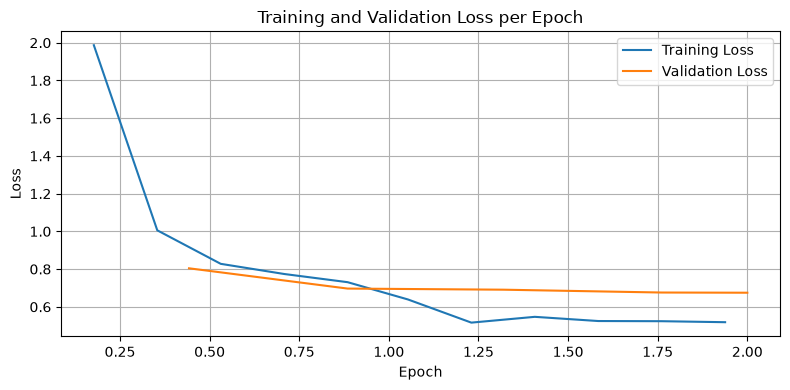

In [22]:
# Extract training and validation loss from the trainer's log history
log_history = trainer.state.log_history

train_losses = [log["loss"] for log in log_history if "loss" in log]
epoch_train = [log["epoch"] for log in log_history if "loss" in log]
eval_losses = [log["eval_loss"] for log in log_history if "eval_loss" in log]
epoch_eval = [log["epoch"] for log in log_history if "eval_loss" in log]

if not train_losses:
    print("No training loss logged yet — run trainer.train() first.")
else:
    plt.figure(figsize=(8, 4))
    plt.plot(epoch_train, train_losses, label="Training Loss")
    if eval_losses:
        plt.plot(epoch_eval, eval_losses, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss per Epoch")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Saving the Fine-Tuned LoRA Adapter and Tokenizer

1. **Saving the LoRA Adapter**: `trainer.model.save_pretrained(...)` saves only the trained LoRA adapter weights, not the full base model. This keeps the artifact very small (typically tens of megabytes) while allowing it to be loaded on top of the base model later.
2. **Saving the Tokenizer**: `tokenizer.save_pretrained(...)` saves the tokenizer configuration and chat template to prevent any tokenization mismatch during inference.

In [23]:
ADAPTER_DIR = "gemma4-sentiment-lora-adapter"

trainer.model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print(f"Adapter and tokenizer saved to ./{ADAPTER_DIR}")

Adapter and tokenizer saved to ./gemma4-sentiment-lora-adapter


Optionally upload the fine-tuned LoRA adapter to the Hugging Face Hub so it can be easily reused later.

In [24]:
if not DEMO:
    adapter_repo = "lmassaron/qlora4b-Gemma4-E2B-finsent-cot"

    trainer.model.push_to_hub(adapter_repo)
    tokenizer.push_to_hub(adapter_repo)

    print(f"Adapter and tokenizer pushed to {adapter_repo}")

## Post-Fine-Tuning Evaluation (CoT Accuracy & Tag Integrity)

Now we re-enable the KV cache for fast generation, run `predict_with_reasoning` on the clean test set using our fine-tuned model, and evaluate both classification metrics and `<sentiment>`/`<reasoning>` tag integrity.

In [25]:
# Re-enable KV cache for faster inference
trainer.model.config.use_cache = True

# Run inference with the exact same settings used for the baseline
y_pred_ft, explanations, ft_integrity = predict_with_reasoning(
    X_test,
    trainer.model.eval(),
    tokenizer,
    device=device,
    max_new_tokens=120,
    batch_size=4,
)
ft_metrics = evaluate(y_true, y_pred_ft, tag_integrity=ft_integrity)

Predicting with Reasoning:   0%|                        | 0/15 [00:00<?, ?it/s]

Predicting with Reasoning:   7%|█               | 1/15 [00:44<10:25, 44.68s/it]

Predicting with Reasoning:  13%|██▏             | 2/15 [01:29<09:40, 44.66s/it]

Predicting with Reasoning:  20%|███▏            | 3/15 [02:13<08:53, 44.49s/it]

Predicting with Reasoning:  27%|████▎           | 4/15 [03:01<08:25, 45.92s/it]

Predicting with Reasoning:  33%|█████▎          | 5/15 [03:48<07:41, 46.16s/it]

... (8 outputs left out)

Predicting with Reasoning:  93%|██████████████ | 14/15 [10:46<00:46, 46.51s/it]

Predicting with Reasoning: 100%|███████████████| 15/15 [11:28<00:00, 44.99s/it]

Predicting with Reasoning: 100%|███████████████| 15/15 [11:28<00:00, 45.88s/it]

Overall Accuracy : 0.867 (86.67%)
Macro F1-Score   : 0.868 (86.78%)
Tag Integrity    : 1.000 (100.00%)
Unparsed ('none'): 0/60 (0.0%)
Accuracy for label 0 (negative): 0.950
Accuracy for label 1 (neutral): 0.750
Accuracy for label 2 (positive): 0.900

Classification Report:
               precision    recall  f1-score   support

    negative       1.00      0.95      0.97        20
     neutral       0.88      0.75      0.81        20
    positive       0.75      0.90      0.82        20

    accuracy                           0.87        60
   macro avg       0.88      0.87      0.87        60
weighted avg       0.88      0.87      0.87        60

Confusion Matrix (rows=true, cols=pred [neg, neu, pos]):
 [[19  0  1]
 [ 0 15  5]
 [ 0  2 18]]


## Qualitative Inspection & Saving Predictions to CSV

Inspecting the generated `<reasoning>` explanations alongside the predicted and ground-truth labels helps verify *why* the model chose each sentiment and makes error analysis much more informative. We print the first 10 test headlines and export the full test set results to `test_predictions_with_reasoning.csv`.

In [26]:
# Compact Before vs. After metrics table for students
comparison_df = pd.DataFrame(
    {
        "Metric": ["Overall Accuracy", "Macro F1-Score", "Tag Integrity", "Unparsed ('none')"],
        "Zero-Shot Base": [
            f"{base_metrics['accuracy']:.2%}",
            f"{base_metrics['macro_f1']:.2%}",
            f"{base_metrics['tag_integrity']:.2%}",
            f"{base_metrics['unparsed']}/{len(y_true)}",
        ],
        "Fine-Tuned (QLoRA)": [
            f"{ft_metrics['accuracy']:.2%}",
            f"{ft_metrics['macro_f1']:.2%}",
            f"{ft_metrics['tag_integrity']:.2%}",
            f"{ft_metrics['unparsed']}/{len(y_true)}",
        ],
        "Delta": [
            f"{ft_metrics['accuracy'] - base_metrics['accuracy']:+.2%}",
            f"{ft_metrics['macro_f1'] - base_metrics['macro_f1']:+.2%}",
            f"{ft_metrics['tag_integrity'] - base_metrics['tag_integrity']:+.2%}",
            f"{ft_metrics['unparsed'] - base_metrics['unparsed']:+d}",
        ],
    }
)
print("=== Before vs. After Fine-Tuning ===\n")
print(comparison_df.to_string(index=False))
print("\n" + "=" * 72 + "\n")

# Print 6 mixed-class test headlines side-by-side (Base vs. Fine-Tuned)
for headline, label, b_pred, b_reason, f_pred, f_reason in zip(
    X_test_df["text"][:6],
    y_true[:6],
    y_pred_base[:6],
    base_reasonings[:6],
    y_pred_ft[:6],
    explanations[:6],
):
    print(f"Headline   : {headline}")
    print(f"True Label : {label}")
    print(f"Base Pred  : {b_pred} | {b_reason}")
    print(f"FT Pred    : {f_pred} | {f_reason}")
    print("-" * 72)

# Save full test predictions and CoT reasoning to CSV for offline analysis
evaluation_df = pd.DataFrame(
    {
        "headline": X_test_df["text"],
        "y_true": y_true,
        "y_pred_base": y_pred_base,
        "y_pred_ft": y_pred_ft,
        "base_tag_integrity": base_integrity,
        "ft_tag_integrity": ft_integrity,
        "base_reasoning": base_reasonings,
        "ft_reasoning": explanations,
    }
)
evaluation_df.to_csv("test_predictions_with_reasoning.csv", index=False)
print("Saved to test_predictions_with_reasoning.csv")

=== Before vs. After Fine-Tuning ===

           Metric Zero-Shot Base Fine-Tuned (QLoRA)  Delta
 Overall Accuracy         78.33%             86.67% +8.33%
   Macro F1-Score         78.58%             86.78% +8.20%
    Tag Integrity        100.00%            100.00% +0.00%
Unparsed ('none')           0/60               0/60     +0


Headline   : Outokumpu 's steel mill in Tornio , in Finland , is the suspected source .
True Label : negative
Base Pred  : negative | The headline suggests a potential operational issue or liability (suspected source) related to a company's asset (steel mill). This introduces risk, potential operational disruption, or regulatory scrutiny, which typically leads to negative sentiment and downward pressure on the stock price and investor confidence.
FT Pred    : negative | The headline suggests that Outokumpu's steel mill in Tornio, Finland, is the source of some issue, which could indicate operational challenges or regulatory scrutiny. Such news can negativel

## Merging the LoRA Adapter into a Standalone Model

This code block **combines the trained LoRA adapter with the original base model to create a single, standalone fine-tuned model**:

1. **`merged_model = trainer.model.merge_and_unload()`**: Mathematically merges the LoRA adapter's weights into the base model's weights and unloads the adapter wrapper.
2. **`merged_model.save_pretrained(...)`**: Saves the complete merged model to disk for direct deployment without needing `peft`.
3. **`tokenizer.save_pretrained(...)`**: Bundles the tokenizer in the same directory.

In [27]:
MERGED_DIR = "merged4q-Gemma4-E2B-model"

# Merge LoRA adapter into base model and save
merged_model = trainer.model.merge_and_unload()
merged_model.save_pretrained(MERGED_DIR)
tokenizer.save_pretrained(MERGED_DIR)
print(f"Merged model and tokenizer saved to ./{MERGED_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model and tokenizer saved to ./merged4q-Gemma4-E2B-model


Push the full merged model to the Hugging Face Hub so it can be loaded directly with `AutoModelForCausalLM.from_pretrained()`.

In [28]:
if not DEMO:
    merged_repo = "lmassaron/merged-LoRA-Gemma4-E2B-finsent-cot"

    merged_model.push_to_hub(merged_repo)
    tokenizer.push_to_hub(merged_repo)

    print(f"Merged model and tokenizer pushed to {merged_repo}")

## Comparing Disk Size: LoRA Adapter vs. Merged Model

This code calculates and prints the total disk size of the two saved artifacts—the lightweight **LoRA adapter** versus the standalone **merged model**—to highlight the storage efficiency of PEFT.

In [29]:
def get_directory_size(directory_path):
    """Calculates the total size of a directory and its subdirectories in bytes."""
    total_size = 0
    for dirpath, _, filenames in os.walk(directory_path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size


bytes_to_gb = 1024 * 1024 * 1024

for directory in [f"./{ADAPTER_DIR}", f"./{MERGED_DIR}"]:
    size_in_bytes = get_directory_size(directory)
    size_in_gb = size_in_bytes / bytes_to_gb
    print(f"Directory '{directory}': {size_in_gb:.2f} GB")

Directory './gemma4-sentiment-lora-adapter': 0.10 GB
Directory './merged4q-Gemma4-E2B-model': 6.31 GB
